# 08 · Apriori pattern mining of drying
**Method** (`src/pattern_mining.py`). Each source is a transaction of items: tertiles of interpretable GIS covariates,
the landscape type, and survey categorical attributes. Frequent itemsets via **apriori** (mlxtend; min support 2 %,
≤ 3 antecedent items) → rules *A → dried* / *A → active*, then:

* one-sided Fisher test + Benjamini–Hochberg FDR;
* **productive rules** only (each item must raise confidence by ≥ 0.03 over every generalisation);
* **ward robustness**: Mantel–Haenszel OR stratified by the 75 wards (rules that hold *within* wards);
* **spatial replication**: lift on held-out spatial blocks;
* ranking by **WRAcc** (subgroup-discovery quality).

The survey's seasonal-flow flag is analysed separately because it may encode dry-season fieldwork.

In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
M, F = ROOT / "results/metrics", ROOT / "results/figures"
def table(name, **kw):
    t = pd.read_csv(M / name, **kw)
    return t.round(4)
def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

In [2]:
display(table("pm_drying_rules_summary.csv")); table("pm_seasonal_flag.csv")

,consequent,n_rules,n_ward_robust,n_reversed_within_wards,median_heldout_replication,median_share_wards_lift_gt1
0,active,2337,1799,4,1.0,0.7778
1,dried,3321,2474,11,1.0,0.6842


,item,support,drying_rate_if_seasonal,drying_rate_if_perennial,mh_or_ward,mh_ci_low,mh_ci_high,share_wards_lift_gt1,n_wards_evaluable
0,flow=seasonal (survey),0.1635,0.6312,0.1963,6.9448,5.7763,8.3495,0.8824,51


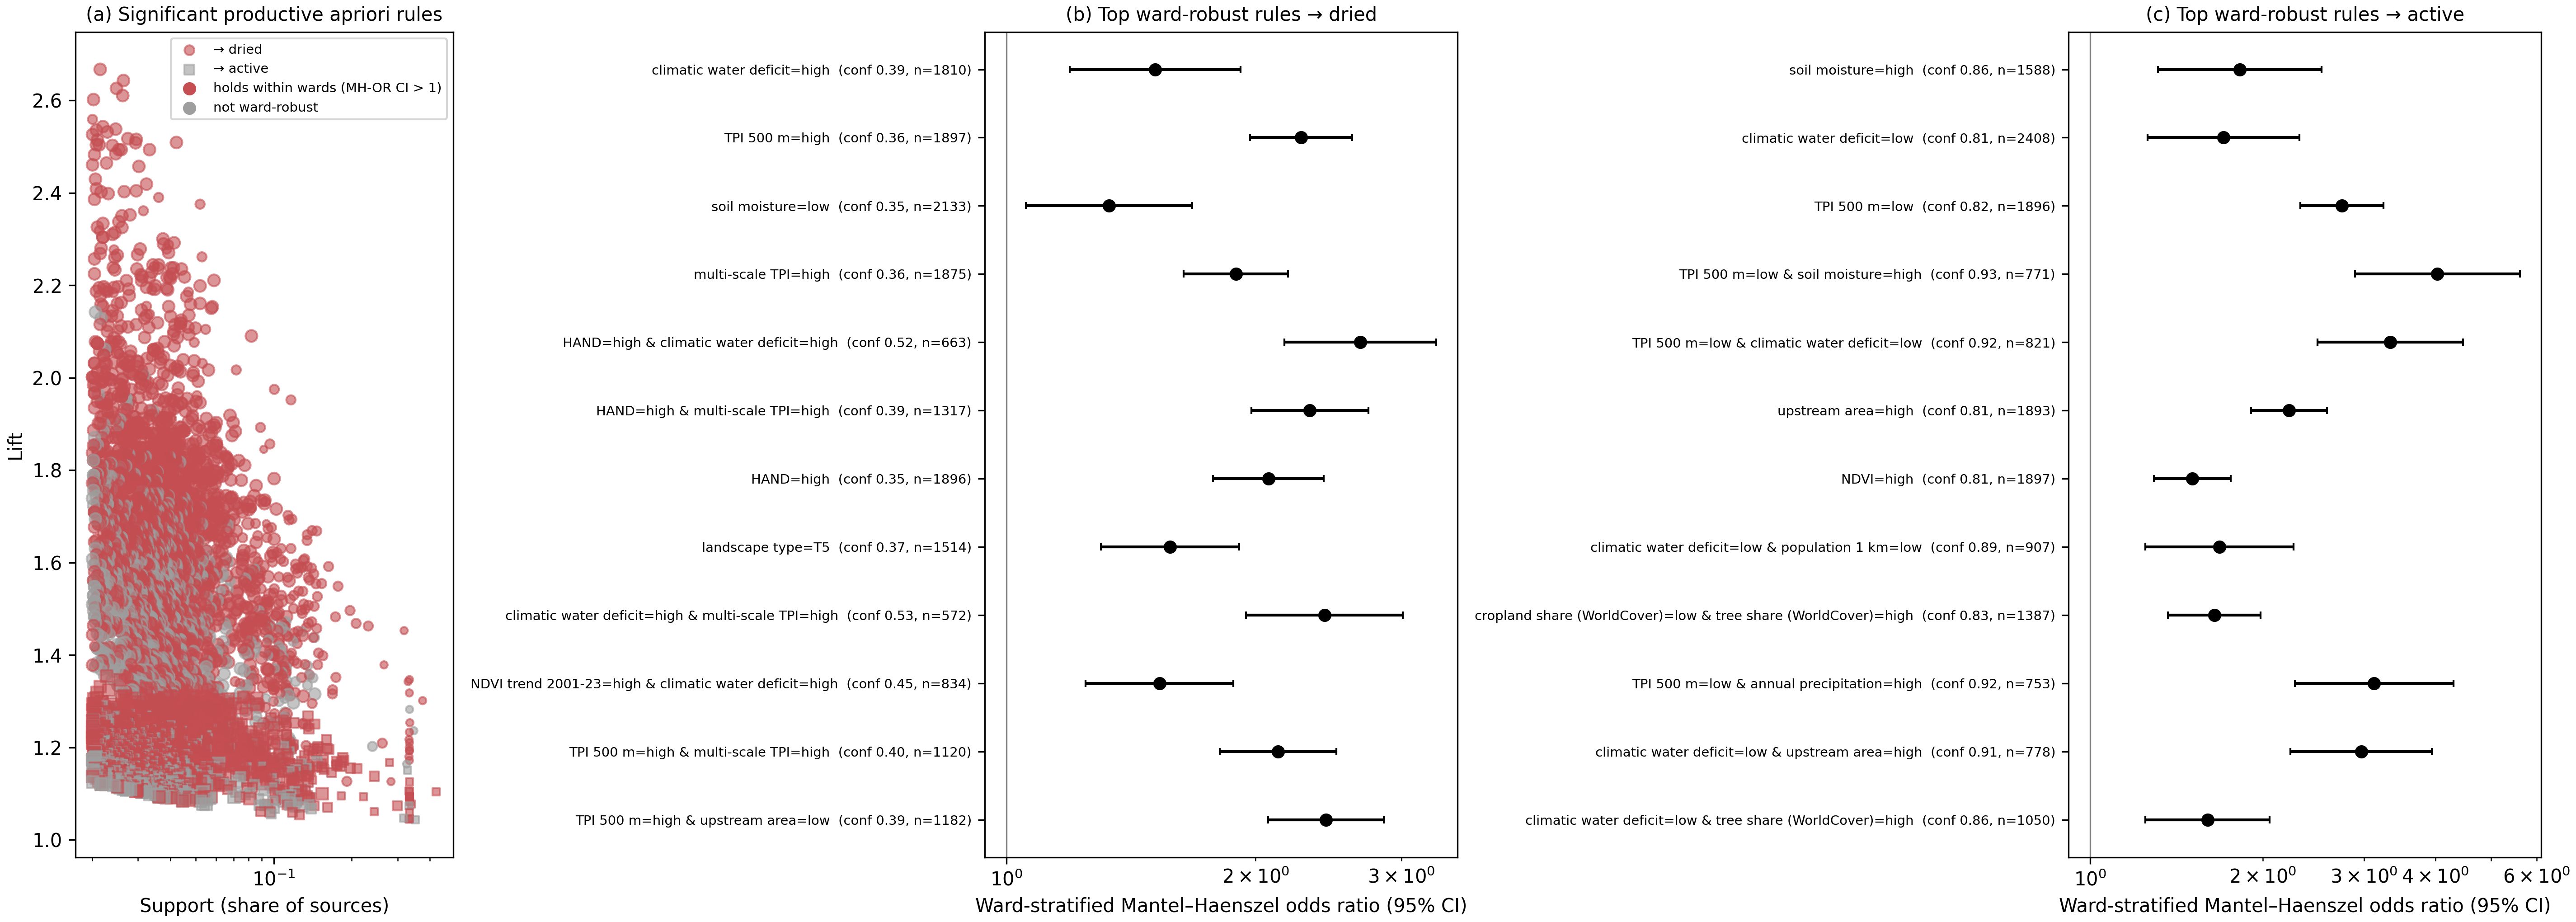

In [3]:
fig("pm_rules.png")

## Top rules for drying (ranked by WRAcc)

In [4]:
r = table("pm_drying_rules.csv")
cols = ["antecedent", "n", "support", "confidence", "lift", "q_bh", "mh_or_ward", "mh_ci_low", "mh_ci_high", "share_wards_lift_gt1", "heldout_replication"]
r[r.consequent == "dried"].sort_values("wracc", ascending=False)[cols].head(30)

,antecedent,n,support,confidence,lift,q_bh,mh_or_ward,mh_ci_low,mh_ci_high,share_wards_lift_gt1,heldout_replication
0,climatic water deficit=high,1810,0.3182,0.3884,1.4527,0.0,1.5128,1.1928,1.9185,0.6667,1.0
1,TPI 500 m=high,1897,0.3335,0.3600,1.3467,0.0,2.2700,1.9704,2.6152,0.8472,1.0
2,soil moisture=low,2133,0.3749,0.3479,1.3011,0.0,1.3305,1.0562,1.6762,0.6400,0.8
3,multi-scale TPI=high,1875,0.3296,0.3589,1.3425,0.0,1.8932,1.6373,2.1890,0.7231,1.0
4,HAND=high & climatic water deficit=high,663,0.1165,0.5219,1.9520,0.0,2.6751,2.1660,3.3039,0.8571,1.0
5,HAND=high & multi-scale TPI=high,1317,0.2315,0.3910,1.4626,0.0,2.3261,1.9758,2.7385,0.7222,1.0
6,HAND=high,1896,0.3333,0.3523,1.3178,0.0,2.0727,1.7763,2.4185,0.6557,1.0
7,landscape type=T5,1514,0.2661,0.3686,1.3785,0.0,1.5775,1.3016,1.9119,0.6585,0.8
9,NDVI trend 2001-23=high & climatic water deficit=high,834,0.1466,0.4460,1.6683,0.0,1.5314,1.2469,1.8808,0.7037,1.0
8,climatic water deficit=high & multi-scale TPI=high,572,0.1005,0.5280,1.9748,0.0,2.4221,1.9469,3.0132,0.8214,1.0


## Top protective rules (→ active)

In [5]:
r[r.consequent == "active"].sort_values("wracc", ascending=False)[cols].head(20)

,antecedent,n,support,confidence,lift,q_bh,mh_or_ward,mh_ci_low,mh_ci_high,share_wards_lift_gt1,heldout_replication
3321,annual precipitation=high,1865,0.3278,0.8429,1.1505,0.0,1.1058,0.8021,1.5246,0.4444,1.0
3322,soil moisture=high,1588,0.2791,0.8552,1.1672,0.0,1.8233,1.3134,2.5313,0.6471,1.0
3323,climatic water deficit=low,2408,0.4233,0.8090,1.1042,0.0,1.7076,1.2586,2.3168,0.6667,0.8
3324,TPI 500 m=low,1896,0.3333,0.8244,1.1252,0.0,2.7452,2.3233,3.2437,0.9016,1.0
3325,TPI 500 m=low & soil moisture=high,771,0.1355,0.9287,1.2676,0.0,4.0311,2.8968,5.6096,0.9565,1.0
3326,TPI 500 m=low & climatic water deficit=low,821,0.1443,0.9160,1.2502,0.0,3.3355,2.4890,4.4698,0.9667,1.0
3327,upstream area=high,1893,0.3327,0.8104,1.1061,0.0,2.2231,1.9088,2.5893,0.8732,1.0
3328,NDVI=high,1897,0.3335,0.8092,1.1045,0.0,1.5061,1.2911,1.7570,0.6567,1.0
3329,climatic water deficit=low & population 1 km=low,907,0.1594,0.8920,1.2174,0.0,1.6803,1.2491,2.2604,0.6296,1.0
3330,cropland share (WorldCover)=low & tree share (WorldCover)=high,1387,0.2438,0.8335,1.1376,0.0,1.6462,1.3675,1.9818,0.7292,1.0


## Simpson-type reversals: pooled lift > 1 but the opposite within wards

In [6]:
r[r.reverses_within_wards][["consequent"] + cols].sort_values("support", ascending=False).head(20)

,consequent,antecedent,n,support,confidence,lift,q_bh,mh_or_ward,mh_ci_low,mh_ci_high,share_wards_lift_gt1,heldout_replication
14,dried,elevation=low,1899,0.3338,0.3428,1.2822,0.0000,0.8025,0.6647,0.9689,0.4054,0.8000
1329,dried,population 1 km=high & precipitation trend=low & slope=low,650,0.1143,0.3262,1.2199,0.0016,0.6511,0.4908,0.8639,0.3333,1.0000
2370,dried,climatic water deficit=low & population 1 km=high & precipitation trend=low,498,0.0875,0.3193,1.1942,0.0196,0.5671,0.3573,0.9001,0.2857,0.6667
4416,active,NDVI trend 2001-23=low & climatic water deficit=low & population 1 km=mid,303,0.0533,0.8251,1.1262,0.0005,0.6835,0.4704,0.9931,0.3889,0.7500
2963,dried,forest loss 2001-14=none & precipitation trend=mid & soil clay=low,290,0.0510,0.3345,1.2511,0.0262,0.5551,0.3898,0.7904,0.1333,1.0000
2206,dried,annual precipitation=low & climatic water deficit=low & soil moisture=mid,249,0.0438,0.3775,1.4120,0.0005,0.5996,0.3771,0.9535,0.2500,0.6667
2205,dried,annual precipitation=low & climatic water deficit=low & population 1 km=high,249,0.0438,0.3775,1.4120,0.0005,0.6114,0.3852,0.9705,0.2500,0.6667
2250,dried,annual precipitation=low & climatic water deficit=low & precipitation trend=low,247,0.0434,0.3765,1.4083,0.0006,0.5955,0.3747,0.9466,0.2500,0.6667
3062,dried,landscape type=T2 & multi-scale TPI=mid,247,0.0434,0.3401,1.2720,0.0275,0.6561,0.4555,0.9448,0.4444,1.0000
4611,active,climatic water deficit=low & population 1 km=mid & precipitation trend=low,232,0.0408,0.8405,1.1472,0.0004,0.5801,0.3710,0.9070,0.1818,1.0000


## Item-level drying rates

In [7]:
table("pm_item_support.csv").sort_values("drying_rate", ascending=False)

,item,support,drying_rate
78,source=pond,0.0916,0.4933
82,surveyed land use=fallow,0.0163,0.4624
85,surveyed land use=settlement,0.0937,0.4503
70,landscape type=T1,0.0536,0.4000
29,climatic water deficit=high,0.3182,0.3884
...,...,...,...
6,TPI 500 m=low,0.3333,0.1756
81,surveyed land use=dense_forest,0.1413,0.1729
26,annual precipitation=high,0.3278,0.1571
32,soil moisture=high,0.2791,0.1448


## Explore: re-mine with your own thresholds

In [8]:
from src.graph_builder import load_master
from src.pattern_mining import tertile_items, categorical_items, mine_rules
df = load_master()
items = {**tertile_items(df), **categorical_items(df)}; items.pop("flow=seasonal (survey)", None)
I = pd.DataFrame(items).astype(bool)
rules, base = mine_rules(I, df.target_dried.to_numpy(), 1, min_support=0.05, max_len=2)   # change me
rules["antecedent"] = [" & ".join(sorted(a)) for a in rules.antecedent]
rules[(rules.q_bh < 0.05) & rules.productive].sort_values("lift", ascending=False).head(15).round(3)

,antecedent,n_items,n,support,confidence,lift,leverage,conviction,wracc,p,q_bh,productive,consequent
719,TPI 500 m=high & source=pond,2,296,0.052,0.635,2.376,0.019,2.008,0.019,0.0,0.0,True,dried
1349,source=pond & upstream area=low,2,301,0.053,0.605,2.262,0.018,1.853,0.018,0.0,0.0,True,dried
1352,surveyed land use=settlement & upstream area=low,2,311,0.055,0.563,2.105,0.016,1.675,0.016,0.0,0.0,True,dried
95,elevation=low & multi-scale TPI=high,2,302,0.053,0.543,2.031,0.015,1.603,0.015,0.0,0.0,True,dried
98,HAND=high & elevation=low,2,408,0.072,0.539,2.017,0.019,1.590,0.019,0.0,0.0,True,dried
873,climatic water deficit=high & multi-scale TPI=high,2,572,0.101,0.528,1.975,0.026,1.552,0.026,0.0,0.0,True,dried
3003,population 1 km=high & surveyed land use=settlement,2,288,0.051,0.524,1.961,0.013,1.540,0.013,0.0,0.0,True,dried
1066,HAND=high & climatic water deficit=high,2,663,0.117,0.522,1.952,0.030,1.532,0.030,0.0,0.0,True,dried
1127,TWI=low & climatic water deficit=high,2,506,0.089,0.506,1.892,0.021,1.483,0.021,0.0,0.0,True,dried
2588,road density=high & surveyed land use=settlement,2,299,0.053,0.505,1.889,0.012,1.480,0.012,0.0,0.0,True,dried
